# 03 · Modelo final × modelo base

**Objetivo:** mostrar, com o conjunto de teste, o que as variáveis novas (`+norm+ciclo`) mudaram em relação
ao modelo base (mesmo XGBoost, mesmos hiperparâmetros, só as variáveis do dia 4).

**Rigor:** o modelo final foi **escolhido por validação cruzada agrupada por motor** (ver `results/`).
O teste aparece aqui só para **descrever** o resultado, não para decidir nada.

> Convenção: `erro = previsão − real`. Positivo = o modelo acha que resta MAIS vida do que resta de fato
> (o erro mais caro em manutenção).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from xgboost import XGBRegressor

SRC = Path("..") / "src"
if SRC.exists():
    sys.path.insert(0, str(SRC.resolve()))

from cmapss.cap_experiment import BEST_XGB
from cmapss.data import RUL_CAP, last_cycle_rows, load_test, load_train
from cmapss.feature_experiment import nasa_score
from cmapss.features_v2 import VARIANTS, build_features, feature_columns_v2
from cmapss.predict import load_model, predict_last_cycle

DATA_DIR = Path("..") / "data"
MODEL_DIR = Path("..") / "models"

model_final, meta = load_model(MODEL_DIR)
windows, slope_windows = tuple(meta["windows"]), tuple(meta["slope_windows"])
print("Variante final:", meta["variant"], "|", len(meta["features"]), "variáveis")

Variante final: +norm+ciclo | 166 variáveis


## 1. Dados e os dois modelos
O modelo base é treinado aqui (mesmos hiperparâmetros do dia 4); o final vem salvo em `models/`.

In [2]:
train = load_train(DATA_DIR)
test, rul_raw = load_test(DATA_DIR, cap=None)       # RUL real do teste, sem teto
sensors = meta["sensors"]

train_f = build_features(train, sensors, windows, slope_windows, meta["n_baseline"])
test_f = build_features(test, sensors, windows, slope_windows, meta["n_baseline"])

cols_base = feature_columns_v2(sensors, windows, slope_windows, **VARIANTS["base"])
model_base = XGBRegressor(n_jobs=-1, random_state=0, **BEST_XGB)
model_base.fit(train_f[cols_base], train_f["RUL"])

last = last_cycle_rows(test_f).reset_index(drop=True)
truth = np.minimum(rul_raw, RUL_CAP)                 # protocolo usual: real limitado a 125
pred = {
    "base": model_base.predict(last[cols_base]),
    "final": model_final.predict(last[meta["features"]]),
}

## 2. Métricas no teste (último ciclo de cada um dos 100 motores)

In [3]:
def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

rows = []
for name, p in pred.items():
    rows.append({
        "modelo": name,
        "RMSE (real ≤125)": rmse(truth, p),
        "RMSE (real sem teto)": rmse(rul_raw, p),
        "score assimétrico": nasa_score(p - truth),
        "% erro positivo": float(np.mean(p - truth > 0)) * 100,
    })
tab = pd.DataFrame(rows).set_index("modelo").round(2)
tab

,RMSE (real ≤125),RMSE (real sem teto),score assimétrico,% erro positivo
modelo,,,,
base,16.16,17.39,645.92,59.0
final,10.98,12.12,171.62,50.0


Lembrete: é **um** modelo por variante (seed 0). A média de várias sementes está nos CSVs de `results/`
(o desvio entre sementes é ≈ ±0,1 de RMSE), então diferenças menores que isso **não** devem ser lidas como melhora.

## 3. Erro por faixa de vida restante real

In [4]:
bins = [-1, 30, 60, 100, 10_000]
labels = ["0–30", "31–60", "61–100", ">100"]
faixa = pd.cut(pd.Series(truth), bins=bins, labels=labels)

linhas = []
for name, p in pred.items():
    err = p - truth
    for lab in labels:
        m = (faixa == lab).to_numpy()
        linhas.append({"modelo": name, "faixa (RUL real)": lab, "n": int(m.sum()),
                       "RMSE": rmse(truth[m], p[m]), "viés médio": float(err[m].mean())})
por_faixa = pd.DataFrame(linhas).round(2)
por_faixa.pivot(index="faixa (RUL real)", columns="modelo", values=["n", "RMSE", "viés médio"])

n         RMSE        viés médio      
modelo            base final   base  final       base final
faixa (RUL real)                                           
0–30              25.0  25.0   4.39   3.59       1.07  1.22
31–60             14.0  14.0  15.85   5.63       8.58 -0.31
61–100            28.0  28.0  23.09  13.77      13.56  5.64
>100              33.0  33.0  14.75  13.46      -6.09 -4.62

## 4. Regressão à média: o viés ainda depende da vida do motor?

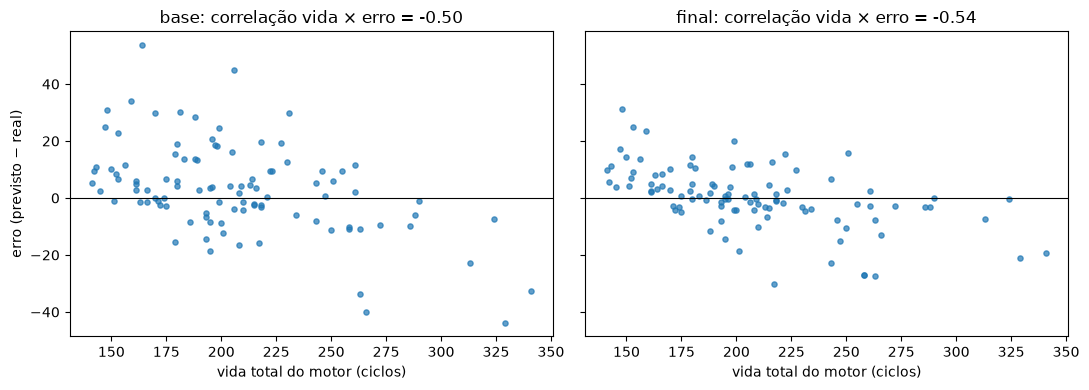

In [5]:
vida_total = last["cycle"].to_numpy() + rul_raw       # ciclos observados + restantes
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, p) in zip(axes, pred.items()):
    err = p - truth
    ax.scatter(vida_total, err, s=14, alpha=0.7)
    ax.axhline(0, color="k", lw=0.8)
    corr = np.corrcoef(vida_total, err)[0, 1]
    ax.set_title(f"{name}: correlação vida × erro = {corr:.2f}")
    ax.set_xlabel("vida total do motor (ciclos)")
axes[0].set_ylabel("erro (previsto − real)")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos descem da esquerda para a direita, motores de vida curta são superestimados e os de vida longa
subestimados (regressão à média). Olhe a correlação nos dois painéis: se continuar parecida, as variáveis novas
**não** resolveram esse problema, e o README deve dizer isso.

## 5. Trajetórias: previsão ao longo do histórico de 3 motores

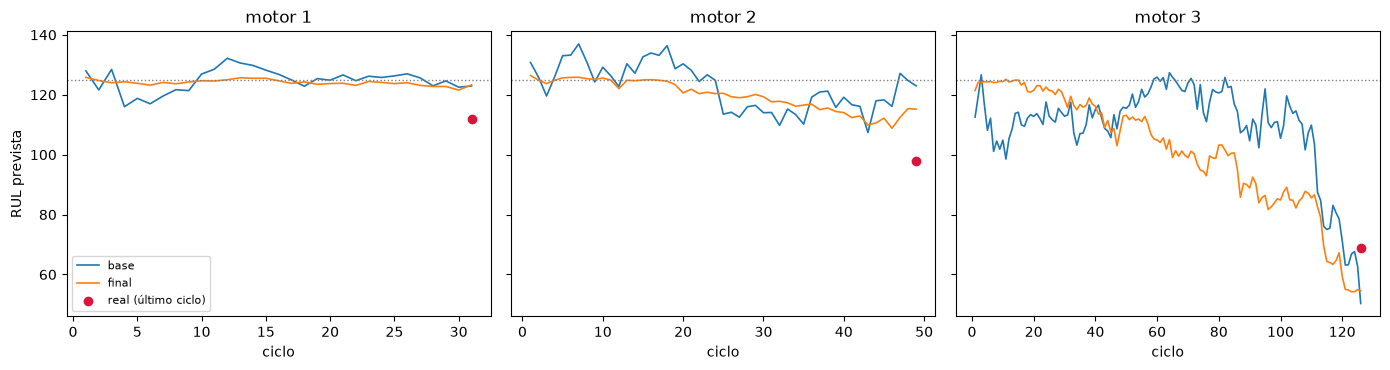

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, unit in zip(axes, sorted(test["unit"].unique())[:3]):
    d = test[test["unit"] == unit]
    f = test_f[test_f["unit"] == unit]
    ax.plot(f["cycle"], model_base.predict(f[cols_base]), lw=1.2, label="base")
    ax.plot(f["cycle"], model_final.predict(f[meta["features"]]), lw=1.2, label="final")
    ax.axhline(RUL_CAP, color="gray", ls=":", lw=1)
    ax.scatter([d["cycle"].max()], [min(rul_raw[int(unit) - 1], RUL_CAP)], color="crimson", zorder=5, label="real (último ciclo)")
    ax.set_title(f"motor {int(unit)}")
    ax.set_xlabel("ciclo")
axes[0].set_ylabel("RUL prevista")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Conclusões

- **Ganho geral:** no teste, o RMSE (real ≤125) caiu de 16,16 (base) para 10,98 (final), e contra a RUL sem teto de 17,39 para 12,12. O score assimétrico caiu de 645,9 para 171,6, e a fração de motores superestimados foi de 59% para 50%. A diferença (≈5 de RMSE) é muito maior que o desvio entre sementes (≈±0,1), e a validação cruzada mostrou o mesmo padrão (≈15,3 → ≈9,7). Portanto o ganho não é ruído de teste.
- **Onde melhorou:** quase tudo veio da faixa intermediária de vida restante. Em 31–60 ciclos o RMSE caiu de 15,85 para 5,63 e o viés de +8,58 para −0,31. Em 61–100 caiu de 23,09 para 13,77 e o viés de +13,56 para +5,64. Na faixa 0–30 (onde o motor já está perto da falha) o erro já era pequeno e mudou pouco (4,39 → 3,59).
- **O que NÃO melhorou:** (1) a regressão à média continua: a correlação entre a vida total do motor e o erro foi de −0,50 (base) para −0,54 (final), ou seja, as variáveis novas reduziram o tamanho dos erros, mas motores de vida curta continuam superestimados e os de vida longa subestimados. Com 100 motores, a diferença entre −0,50 e −0,54 não é relevante. (2) Na faixa >100 o RMSE quase não mudou (14,75 → 13,46) e o viés continua negativo (−6,09 → −4,62). (3) O viés positivo ainda existe: em 61–100 o modelo final superestima em média 5,6 ciclos, e 50% dos motores ainda têm a RUL superestimada, que é o erro mais caro em manutenção.
- **Trajetórias:** o modelo final é mais estável que o base ao longo do histórico (curvas menos ruidosas). Nos motores 1 e 2 ele ainda superestima a RUL no último ciclo (motor 2: ~115 previstos contra 98 reais). No motor 3 ele subestima no fim (~55 contra ~69).
- **Hipótese (não testada isoladamente):** o ganho é compatível com a normalização pelo nível inicial do motor, que reduz diferenças de "ponto de partida" entre motores. A ablação do dia 6 é a evidência desse efeito; este notebook não isola a causa.
- **Limitações:** dados simulados, condição de operação única (FD001), alvo limitado a 125 (o modelo nunca prevê acima disso), um único modelo por variante neste notebook (seed 0) e apenas 100 motores no teste. Não deve ser lido como validação para motores reais.